# Experiment 7: analysis of the Webots runs
Reads the trajectory CSVs in `runs/` (written by `tools/run_experiment.py`, see NOTES.md) and computes
the same metrics as the project's `analysis/metrics.py`: path length, mean speed, stuck % (< 1 cm/s),
and coverage (10 cm cells for the 1.6 m swarm arena, 50 cm cells for the 8 m Pioneer room).

In [1]:
import csv, glob, json, math, os, re
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

GRID = {"swarm": (0.8, 0.1), "pioneer": (4.0, 0.5)}     # half-width (m), cell (m)

def load(path):
    tracks = defaultdict(list)
    with open(path) as f:
        for r in csv.DictReader(f):
            tracks[r["robot"]].append((float(r["t"]), float(r["x"]), float(r["y"])))
    return tracks

def metrics(path, world, every=1):
    """every > 1 keeps only every k-th logged pose (to compare runs logged at different rates)."""
    half, cell = GRID[world]
    n = int(round(2*half/cell))
    visited, robots = set(), {}
    for name, p in sorted(load(path).items()):
        p = p[::every]
        length, stuck = 0.0, 0
        for (t0, x0, y0), (t1, x1, y1) in zip(p, p[1:]):
            d = math.hypot(x1 - x0, y1 - y0)
            length += d
            stuck += d/max(t1 - t0, 1e-9) < 0.01
        for _, x, y in p:
            visited.add((min(n - 1, int((x + half)/cell)), min(n - 1, int((y + half)/cell))))
        dur = p[-1][0] - p[0][0]
        robots[name] = dict(path=length, speed=length/dur, stuck=100*stuck/max(len(p) - 1, 1), duration=dur)
    return dict(robots=robots, coverage=100*len(visited)/n**2)

runs = {}
for f in sorted(glob.glob("runs/*.csv")):
    label = os.path.splitext(os.path.basename(f))[0]
    world = "pioneer" if label.startswith("pioneer") else "swarm"
    runs[label] = metrics(f, world)
print(len(runs), "runs loaded")

def setting(label):                       # 'swarm_cruise0.9_r2' -> 'swarm_cruise0.9'
    return re.sub(r"_r\d+$", "", label)

def swarm_row(m):
    rb = m["robots"].values()
    return dict(path=np.mean([r["path"] for r in rb]), speed=np.mean([r["speed"] for r in rb]),
                stuck_mean=np.mean([r["stuck"] for r in rb]), stuck_worst=max(r["stuck"] for r in rb),
                coverage=m["coverage"], duration=min(r["duration"] for r in rb))

def mean_sd(rows, key):
    v = np.array([r[key] for r in rows]); return float(v.mean()), float(v.std(ddof=1)) if v.size > 1 else 0.0

35 runs loaded


## Table 7.1: swarm, default vs cruise = 0.9 (per-robot mean path and speed; mean and worst stuck)

In [2]:
R = {"table71": {}, "table72": {}, "ex1": {}, "ex4": {}}
for s in ("swarm_default", "swarm_cruise0.9"):
    rows = [dict(run=int(l[-1]), **swarm_row(runs[l])) for l in runs if setting(l) == s]
    R["table71"][s] = dict(runs=rows, **{k: mean_sd(rows, k) for k in ("path", "speed", "stuck_mean", "stuck_worst", "coverage")})
    for r in rows:
        print(f"{s:<18} run {r['run']}: path {r['path']:.2f} m, {r['speed']:.3f} m/s, stuck mean {r['stuck_mean']:.1f}% "
              f"worst {r['stuck_worst']:.1f}%, coverage {r['coverage']:.0f}%")
    t = R["table71"][s]
    print(f"   mean ± SD: path {t['path'][0]:.2f}±{t['path'][1]:.2f}, coverage {t['coverage'][0]:.1f}±{t['coverage'][1]:.1f}, "
          f"worst stuck {t['stuck_worst'][0]:.1f}±{t['stuck_worst'][1]:.1f}")

swarm_default      run 1: path 6.15 m, 0.051 m/s, stuck mean 7.1% worst 29.9%, coverage 80%
swarm_default      run 2: path 6.15 m, 0.051 m/s, stuck mean 7.1% worst 29.9%, coverage 80%
swarm_default      run 3: path 6.15 m, 0.051 m/s, stuck mean 7.1% worst 29.9%, coverage 80%
   mean ± SD: path 6.15±0.00, coverage 80.5±0.0, worst stuck 29.9±0.0
swarm_cruise0.9    run 1: path 10.66 m, 0.089 m/s, stuck mean 3.6% worst 4.8%, coverage 86%
swarm_cruise0.9    run 2: path 10.66 m, 0.089 m/s, stuck mean 3.6% worst 4.8%, coverage 86%
swarm_cruise0.9    run 3: path 10.66 m, 0.089 m/s, stuck mean 3.6% worst 4.8%, coverage 86%
   mean ± SD: path 10.66±0.00, coverage 85.9±0.0, worst stuck 4.8±0.0


## Table 7.2: Pioneer, default and two safety-bubble settings (3 runs each)

In [3]:
for s in ("pioneer_default", "pioneer_bubble0.15", "pioneer_bubble0.9"):
    rows = []
    for l in runs:
        if setting(l) == s:
            r = runs[l]["robots"]["pioneer"]
            rows.append(dict(run=int(l[-1]), path=r["path"], stuck=r["stuck"], coverage=runs[l]["coverage"]))
    R["table72"][s] = dict(runs=rows, **{k: mean_sd(rows, k) for k in ("path", "stuck", "coverage")})
    for r in rows:
        print(f"{s:<20} run {r['run']}: path {r['path']:.1f} m, stuck {r['stuck']:.1f}%, coverage {r['coverage']:.0f}%")

pioneer_default      run 1: path 83.6 m, stuck 0.0%, coverage 23%
pioneer_default      run 2: path 83.6 m, stuck 0.0%, coverage 23%
pioneer_default      run 3: path 83.6 m, stuck 0.0%, coverage 23%
pioneer_bubble0.15   run 1: path 13.4 m, stuck 78.1%, coverage 12%
pioneer_bubble0.15   run 2: path 13.4 m, stuck 78.1%, coverage 12%
pioneer_bubble0.15   run 3: path 13.4 m, stuck 78.1%, coverage 12%
pioneer_bubble0.9    run 1: path 82.0 m, stuck 0.0%, coverage 24%
pioneer_bubble0.9    run 2: path 82.0 m, stuck 0.0%, coverage 24%
pioneer_bubble0.9    run 3: path 82.0 m, stuck 0.0%, coverage 24%


## Exercise 1 (speed vs safety) and exercise 4 (time step)
The logger samples every 10 steps, i.e. every 0.08 / 0.32 / 0.64 s at 8 / 32 / 64 ms. Path length,
the < 1 cm/s stuck test and coverage all depend on the sampling interval, so for exercise 4 every run is
resampled to the same 0.64 s grid (every 8th pose at 8 ms, every 2nd at 32 ms) before comparing.

In [4]:
CRUISE = [0.2, 0.4, 0.5, 0.6, 0.8, 1.0]          # 0.5 is the default: reuse the default runs
for c in CRUISE:
    s = "swarm_default" if c == 0.5 else f"ex1_cruise{c}"
    rows = [swarm_row(runs[l]) for l in runs if setting(l) == s]
    R["ex1"][c] = {k: mean_sd(rows, k) for k in ("coverage", "stuck_worst", "path")} | {"n": len(rows)}
    print(c, {k: tuple(round(x, 1) for x in v) if isinstance(v, tuple) else v for k, v in R["ex1"][c].items()})
for s, ts, every in (("ex4_ts8", 8, 8), ("swarm_default", 32, 2), ("ex4_ts64", 64, 1)):
    rows = [swarm_row(metrics(f"runs/{l}.csv", "swarm", every)) for l in runs if setting(l) == s]
    R["ex4"][ts] = {k: mean_sd(rows, k) for k in ("coverage", "stuck_mean", "stuck_worst", "path")} | {"n": len(rows)}
    print("basicTimeStep", ts, {k: tuple(round(x, 1) for x in v) if isinstance(v, tuple) else v for k, v in R["ex4"][ts].items()})

0.2 {'coverage': (56.2, 0.0), 'stuck_worst': (0.3, 0.0), 'path': (2.7, 0.0), 'n': 3}
0.4 {'coverage': (77.0, 0.0), 'stuck_worst': (1.6, 0.0), 'path': (5.2, 0.0), 'n': 3}
0.5 {'coverage': (80.5, 0.0), 'stuck_worst': (29.9, 0.0), 'path': (6.2, 0.0), 'n': 3}
0.6 {'coverage': (80.9, 0.0), 'stuck_worst': (3.2, 0.0), 'path': (7.6, 0.0), 'n': 3}
0.8 {'coverage': (83.6, 0.0), 'stuck_worst': (4.0, 0.0), 'path': (9.6, 0.0), 'n': 3}
1.0 {'coverage': (85.9, 0.0), 'stuck_worst': (6.1, 0.0), 'path': (11.5, 0.0), 'n': 3}


basicTimeStep 8 {'coverage': (80.1, 0.0), 'stuck_mean': (0.0, 0.0), 'stuck_worst': (0.0, 0.0), 'path': (6.8, 0.0), 'n': 2}
basicTimeStep 32 {'coverage': (80.5, 0.0), 'stuck_mean': (6.7, 0.0), 'stuck_worst': (29.4, 0.0), 'path': (6.1, 0.0), 'n': 3}
basicTimeStep 64 {'coverage': (63.3, 0.0), 'stuck_mean': (11.0, 0.0), 'stuck_worst': (15.6, 0.0), 'path': (5.1, 0.0), 'n': 3}


## Figures

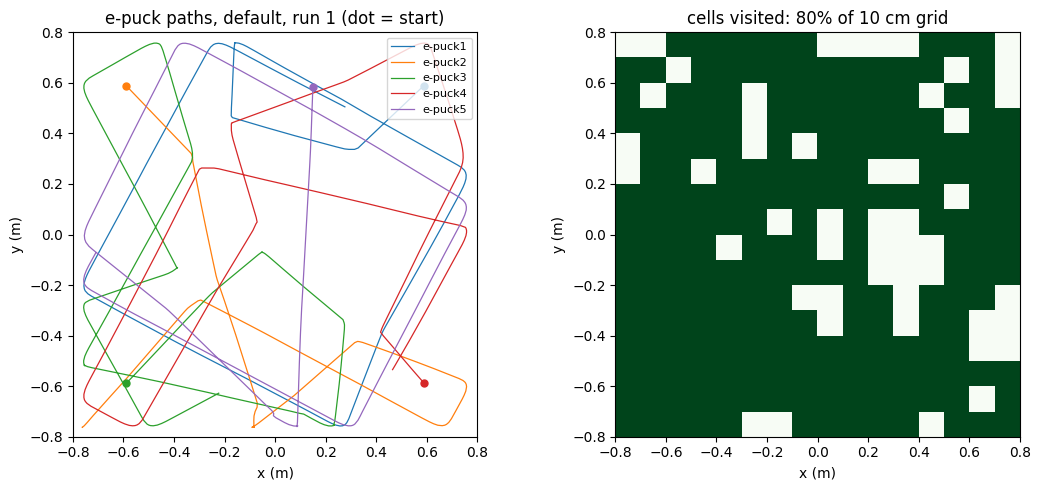

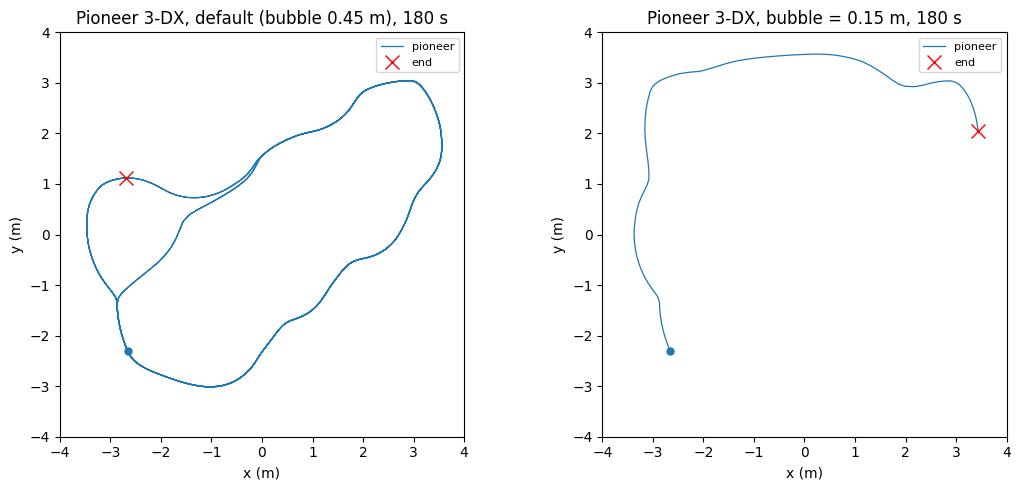

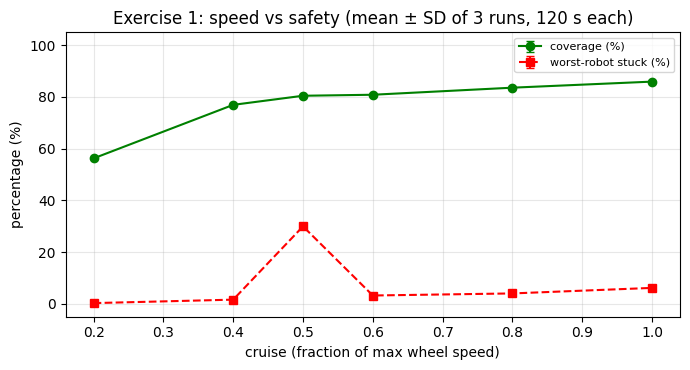

In [5]:
def plot_paths(ax, tracks, half, title):
    for name, p in sorted(tracks.items()):
        p = np.array(p)
        ln, = ax.plot(p[:, 1], p[:, 2], lw=0.9, label=name)
        ax.plot(p[0, 1], p[0, 2], "o", ms=5, color=ln.get_color())
    ax.set(xlim=(-half, half), ylim=(-half, half), aspect="equal", xlabel="x (m)", ylabel="y (m)", title=title)

def plot_coverage(ax, tracks, half, cell):
    allp = np.vstack([np.array(p)[:, 1:] for p in tracks.values()])
    n = int(round(2*half/cell))
    Hh, _, _ = np.histogram2d(allp[:, 0], allp[:, 1], bins=n, range=[[-half, half], [-half, half]])
    ax.imshow(Hh.T > 0, origin="lower", extent=(-half, half, -half, half), cmap="Greens")
    ax.set(aspect="equal", xlabel="x (m)", ylabel="y (m)",
           title=f"cells visited: {100*(Hh > 0).mean():.0f}% of {cell*100:.0f} cm grid")

# Figure 7.2: swarm default run 1
tr = load("runs/swarm_default_r1.csv")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5))
plot_paths(a1, tr, 0.8, "e-puck paths, default, run 1 (dot = start)"); a1.legend(fontsize=8)
plot_coverage(a2, tr, 0.8, 0.1)
fig.tight_layout(); fig.savefig("figs/fig7_2_swarm_trajectories.png", dpi=150); plt.show()

# Figure 7.3: Pioneer default run 1 and bubble = 0.15 run 1
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for ax, l, t in ((axs[0], "pioneer_default_r1", "default (bubble 0.45 m)"),
                 (axs[1], "pioneer_bubble0.15_r1", "bubble = 0.15 m")):
    tr = load(f"runs/{l}.csv")
    plot_paths(ax, tr, 4.0, f"Pioneer 3-DX, {t}, 180 s")
    p = np.array(tr["pioneer"]); ax.plot(p[-1, 1], p[-1, 2], "x", ms=10, color="r", label="end")
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figs/fig7_3_pioneer_trajectory.png", dpi=150); plt.show()

# Figure 7.4: exercise 1
c = np.array(CRUISE)
cov = np.array([R["ex1"][x]["coverage"] for x in CRUISE]); st = np.array([R["ex1"][x]["stuck_worst"] for x in CRUISE])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(c, cov[:, 0], yerr=cov[:, 1], fmt="o-", color="g", capsize=3, label="coverage (%)")
ax.errorbar(c, st[:, 0], yerr=st[:, 1], fmt="s--", color="r", capsize=3, label="worst-robot stuck (%)")
ax.set(xlabel="cruise (fraction of max wheel speed)", ylabel="percentage (%)", ylim=(-5, 105),
       title="Exercise 1: speed vs safety (mean ± SD of 3 runs, 120 s each)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figs/fig7_4_exercise1.png", dpi=150); plt.show()

In [6]:
json.dump(R, open("results.json", "w"), indent=1, default=float)